In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

os.environ["NUMBA_THREADING_LAYER"] = "tbb"

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RegularGridInterpolator, griddata, interp1d
import cartopy.crs as ccrs
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.ticker as mticker
import matplotlib.colors as colors
from matplotlib.cm import ScalarMappable
import gc

import cmocean
from netCDF4 import Dataset
#from datetime import date, timedelta
import xarray as xr
## . . For animation
from matplotlib import animation
from IPython.display import HTML, Image
import geopandas
import rioxarray as rio
from shapely.geometry import mapping, shape
import pandas as pd
from pyproj import Transformer
from numba import jit, prange, set_num_threads, threading_layer, get_num_threads
set_num_threads(24)
import time

# Load Data

In [3]:
path = os.path.dirname(os.path.dirname(os.getcwd()))

In [4]:
IMBIE = geopandas.read_file(path+"/Inputs/ANT_Basins_IMBIE2_v1.6/ANT_Basins_IMBIE2_v1.6.shp", crs="epsg:3031")
scripps = geopandas.read_file(path+"/Inputs/scripps_GL/scripps_antarctica_polygons_v1.shp", crs="epsg:3031")
scripps_gl = scripps.loc[scripps['Id'].astype(int) == 1]

/Users/rharis/miniforge3/envs/gw_exfil/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: driver ESRI Shapefile does not support open option CRS
  return ogr_read(
/Users/rharis/miniforge3/envs/gw_exfil/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: driver ESRI Shapefile does not support open option CRS
  return ogr_read(


In [5]:
da = rio.open_rasterio(path+'/Inputs/smith_product.tif')
dhdt = da.variable.data[0]

dhdt_forcing = dhdt/(3600*24*365.25) # converts to m/s

In [6]:
bedmachine = xr.open_dataset(path+"/Inputs/BedMachineAntarctica-v3.nc")
bm_x, bm_y = np.meshgrid(bedmachine.x, bedmachine.y)
sm_x, sm_y = np.meshgrid(da.x, da.y)
interp = RegularGridInterpolator(points=[bedmachine.x.values,bedmachine.y.values], values=bedmachine["thickness"].values.T, method="linear", fill_value=np.nan, bounds_error = False)
bm_new = interp((sm_x, sm_y))

# Parameters

In [7]:
year = 3600*24*365.25

xi = 0.2 #Skempton's constant
rhoi = 920
rhow = 1000
g = 9.81
mu_w = 1e-3
S = 1e-6
perm=1e-13
K_t = perm*rhow*g/mu_w
D = K_t/S

L = 40e3
dz = 100
dt = 3600*12
tf = year*16
nt = int(np.round(tf/dt))
ny,nx = np.shape(dhdt)
#save each 12 days instead
intSave = 24

In [8]:
n_save = int(nt/intSave)+1
n_save

488

In [8]:
C_D = D*dt/(dz*dz)
C_D

4.237920000000001

In [9]:
#assumes bedmachine ice thickness is final thickness at 2019, constant thinning from Smith et al. 2020
thk_init = bm_new - 16*dhdt #dhdt in m/yr here

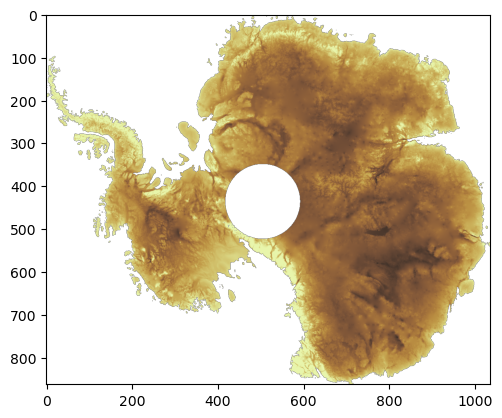

In [15]:
plt.figure()
ax = plt.subplot(1,1,1)
plt.imshow(thk_init,cmap = cmocean.cm.turbid,vmin=0,vmax = 5000)

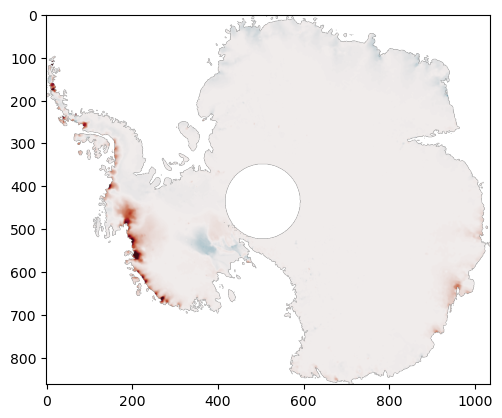

In [17]:
plt.figure()
ax = plt.subplot(1,1,1)
plt.imshow(dhdt,cmap = cmocean.cm.balance_r,vmin=-3,vmax = 3)

# TDMA Model

In [ ]:
@jit(nopython=True)
def TDMA(ac,bc,cc,dc):
        #a : left coefficients (i-1)
        #b : center coefficients (i)
        #c : right coefficients (i+1)
        #d : right hand vector 
        #xc : solution at t+1

        nf = len(dc) #number of equations

        #Forward Sweep
        for it in range(1,nf):
            mc = ac[it]/bc[it-1]
            bc[it] = bc[it] - mc*cc[it-1] #Overwrites bc
            dc[it] = dc[it] - mc*dc[it-1] #overwrites d

        #Backsubstitution sweep
        xc = np.empty(nf, dtype=np.float64)
        xc[-1] = dc[-1]/bc[-1]

        for il in range(nf-2,-1,-1):
            xc[il] = (dc[il] - cc[il]*xc[il+1])/bc[il]
        return xc

@jit(nopython=True)
def solve_diffusion(h,C_D,Svec,TB_k,TB_knext):
        #h : head at time t
        #C_D : diffusion coefficient = D*dt/dz**2

        n = len(h)
        #Set up coefficients
        aa = -0.5*C_D*np.ones(n-1, dtype=np.float64)
        bb = (1+C_D)*np.ones(n-1, dtype=np.float64)
        cc = -0.5*C_D*np.ones(n-1, dtype=np.float64)

        #Set up rhs solution
        dd = np.zeros(n-1, dtype=np.float64)

        dd[1:n-2] = 0.5*C_D*h[3:n] + (1-C_D)*h[2:n-1] + 0.5*C_D*h[1:n-2] + Svec[2:-1]

        #Top Boundary Condition
        dd[0] = 0.5*C_D*h[2] + (1-C_D)*h[1] + 0.5*C_D*(TB_k + TB_knext)+ Svec[1]

        #Bottom Boundary Condition
        dd[-1] = (1-0.5*C_D)*h[-1] + 0.5*C_D*h[-2] + Svec[-1]
        bb[-1] = 1 + 0.5*C_D

        # Call Solver
        h[1:] = TDMA(aa,bb,cc,dd)

        return h



@jit(nopython=True, parallel=True)
def run_model(intSave,xi,perm,S,dt,dz,L,nt,ny,nx,dhdt,thk_init):

    rhoi = 920
    rhow = 1000
    g = 9.81
    mu_w = 1e-3

    K_t = perm*rhow*g/mu_w
    D = K_t/S
    
    nz = int(L/dz) + 1
    n_save = int(nt/intSave) + 2
    ncols = nx*ny
    sfc_flux_array = np.zeros((n_save,ny,nx))

    C_D = D*dt/(dz*dz)

    #Initial head condition is scaled to ratio of ice to water densities
    for col in prange(ncols):
        x_idx = col % nx
        y_idx = col // nx
        thk_m = thk_init[y_idx,x_idx]
        dhdt_t = dhdt[y_idx,x_idx] #constant, dhdt is in m/s
        
        if np.isnan(thk_m) or np.isnan(dhdt_t):
             sfc_flux_array[:,y_idx,x_idx] = np.nan
        else:
            Svec = np.zeros(nz, dtype=np.float64)
            h = np.ones(nz, dtype=np.float64)
            hm = thk_m*(rhoi/rhow)*h
            for k in range(nt+1):
                TB_k = (rhoi/rhow)*thk_m
                TB_knext = (rhoi/rhow)*(thk_m + dt*dhdt_t)
                hm[0] = TB_k
                Svec[:] = dt*xi*(rhoi/rhow)*dhdt_t
                hm = solve_diffusion(hm,C_D,Svec,TB_k,TB_knext)
                hm[0] = TB_knext
                thk_m = thk_m + dt*dhdt_t # Adds dh due to instantaneous dhdt*dt in m
                
                if k%intSave == 0:
                    sfc_flux_array[int(k/intSave)+1,y_idx,x_idx] = K_t*(hm[0]-hm[1])/dz

    return sfc_flux_array

# Run Model

In [ ]:
start = time.time()
sfc_flux_array = run_model(intSave,xi,perm,S,dt,dz,L,nt,ny,nx,dhdt_forcing.astype(np.float64),thk_init.astype(np.float64))
end = time.time()
print(end-start)

In [ ]:
time_save = np.arange(0,np.shape(sfc_flux_array)[0],1)

data_q = xr.DataArray(
    sfc_flux_array,
    coords={"time" : time_save, "x" : da.x.values, "y" : da.y.values},
    dims=["time","y","x"]
)
data_q.to_netcdf("validation_qflux_29mar.nc", mode="w", format="NETCDF4")


In [ ]:
sfc_flux_array = xr.open_dataarray("validation_qflux_9apr.nc")

In [10]:
sfc_flux_final = xr.open_dataarray("validation_qflux_9apr_final.nc")

In [31]:
np.nanmin(-1000*year*sfc_flux_array.values)

np.float64(-19.040615972578948)

Text(0.5, 1.0, 'Numerical, k=1e-13')

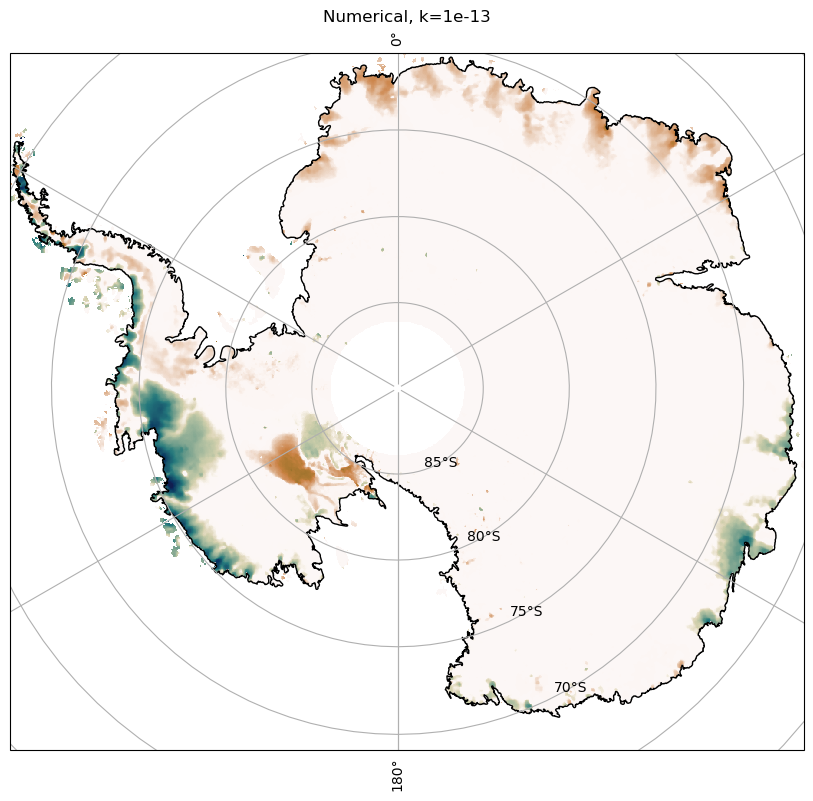

In [11]:

projection = ccrs.SouthPolarStereo()
fig = plt.figure(figsize=(16,9), constrained_layout=True)
ax = plt.subplot(1,2,1, projection=projection)
p1 = ax.pcolormesh(da.x,da.y,-1000*year*sfc_flux_final, cmap=cmocean.cm.tarn,
                   norm=colors.SymLogNorm(linthresh=1.0, linscale=0.03,vmin=-100,vmax=100))
scripps_gl.plot(ax=ax, edgecolor="black",linewidth=1,facecolor="none")
ax.gridlines(draw_labels=True)
plt.title(f"Numerical, k={perm}")

In [22]:
dt = 3600*2
tf = year*0.25
nt = int(np.round(tf/dt))
ny,nx = np.shape(dhdt)
#save each 12 days instead
intSave = 144
for k in range(nt-1):
    if k%intSave == 0:
        print(int(k/intSave))

0
1
2
3
4
5
6
7


# Numerical vs Analytic Solution

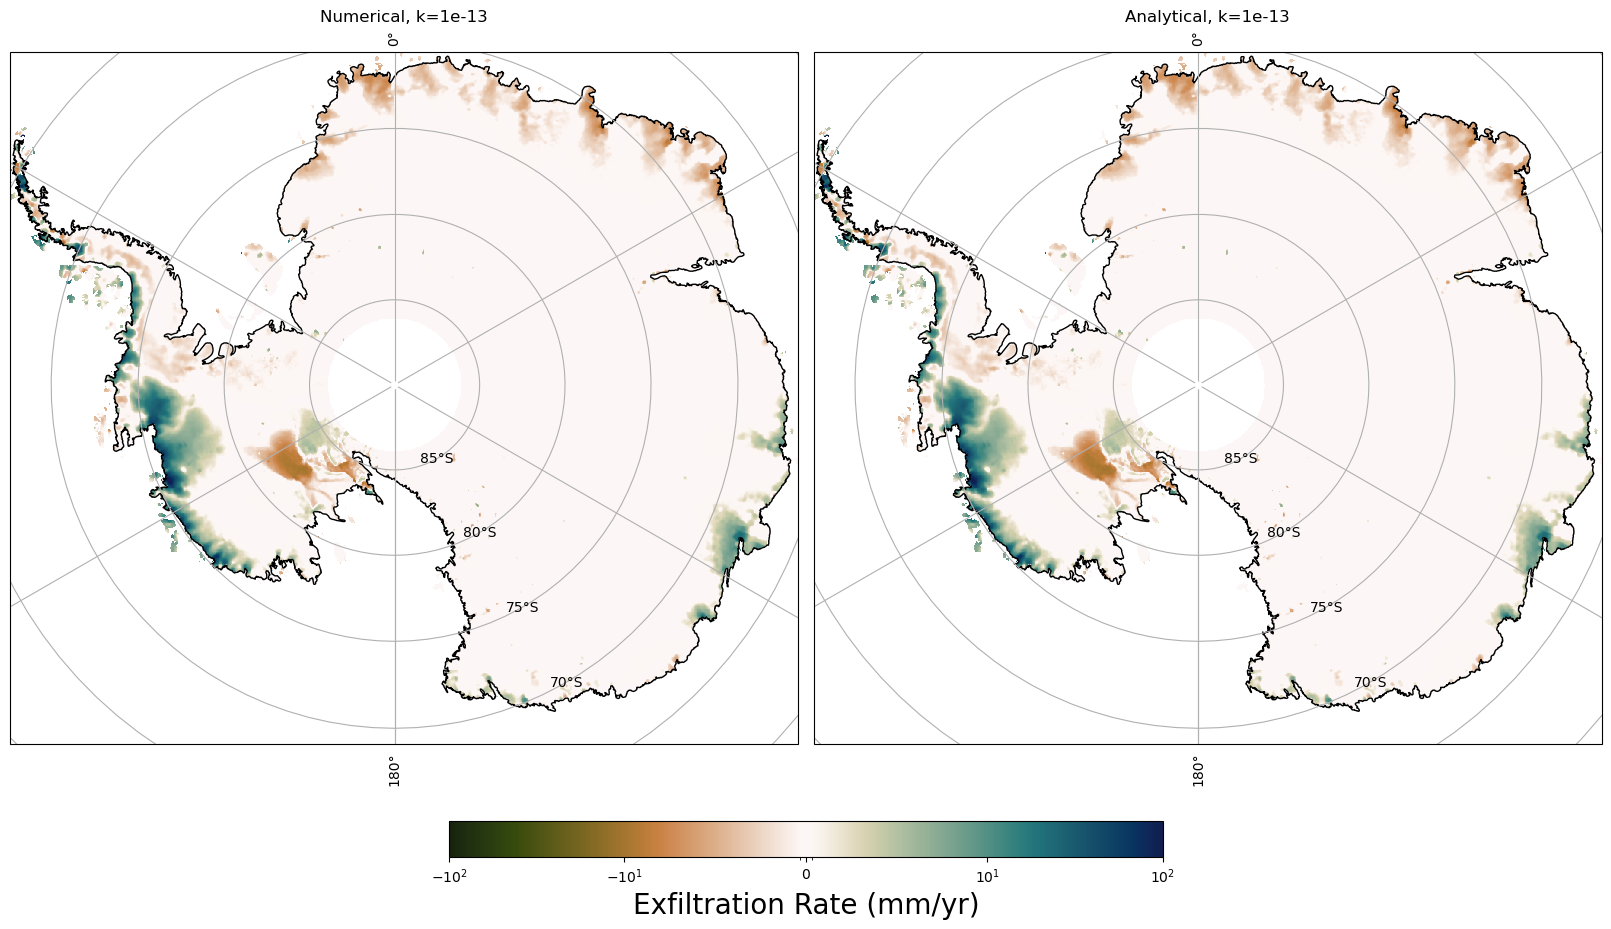

In [13]:
exfil_analytic = -2*(1-xi)*(rhoi/rhow)*(dhdt)*(K_t*S*16*year/np.pi)**0.5

projection = ccrs.SouthPolarStereo()
fig = plt.figure(figsize=(16,9), constrained_layout=True)
ax = plt.subplot(1,2,1, projection=projection)
p1 = ax.pcolormesh(da.x,da.y,-1000*year*sfc_flux_final, cmap=cmocean.cm.tarn,
                   norm=colors.SymLogNorm(linthresh=1.0, linscale=0.03,vmin=-100,vmax=100))
scripps_gl.plot(ax=ax, edgecolor="black",linewidth=1,facecolor="none")
ax.gridlines(draw_labels=True)
plt.title(f"Numerical, k={perm}")

ax2 = plt.subplot(1,2,2, projection=projection)
p2 = ax2.pcolormesh(da.x,da.y,1000*exfil_analytic, cmap=cmocean.cm.tarn,
                   norm=colors.SymLogNorm(linthresh=1.0, linscale=0.03,vmin=-100,vmax=100))
scripps_gl.plot(ax=ax2, edgecolor="black",linewidth=1,facecolor="none")
ax2.gridlines(draw_labels=True)
plt.title(f"Analytical, k={perm}")


cbar = fig.colorbar(
    p1,                             # or p2, same cmap/norm
    ax=[ax, ax2],                  # applies to both subplots
    orientation='horizontal',
    fraction=0.05,                  # thickness
    pad=0.05,                       # distance from subplots
    ticks=[-100, -10, 0, 10, 100]
)
cbar.set_label("Exfiltration Rate (mm/yr)", fontsize=20)


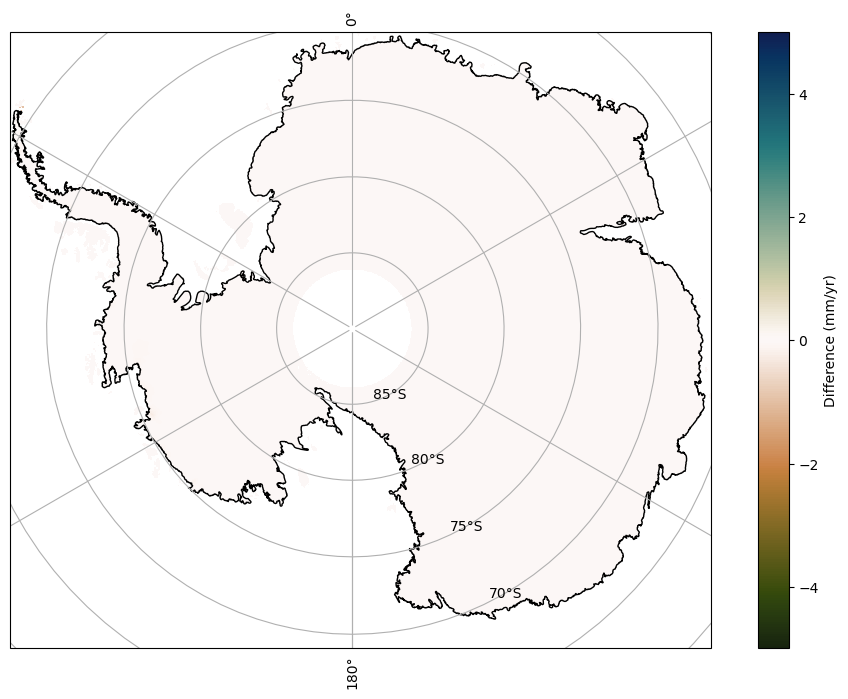

In [14]:
diff = -1000*year*sfc_flux_final - 1000*exfil_analytic

projection = ccrs.SouthPolarStereo()
fig = plt.figure(figsize=(12,8))
ax = plt.subplot(1,1,1, projection=projection)
p1 = ax.pcolormesh(da.x,da.y,diff, cmap=cmocean.cm.tarn,vmin = -5, vmax = 5)
scripps_gl.plot(ax=ax, edgecolor="black",linewidth=1,facecolor="none")
ax.gridlines(draw_labels=True)
cb = plt.colorbar(p1)
cb.set_label("Difference (mm/yr)")

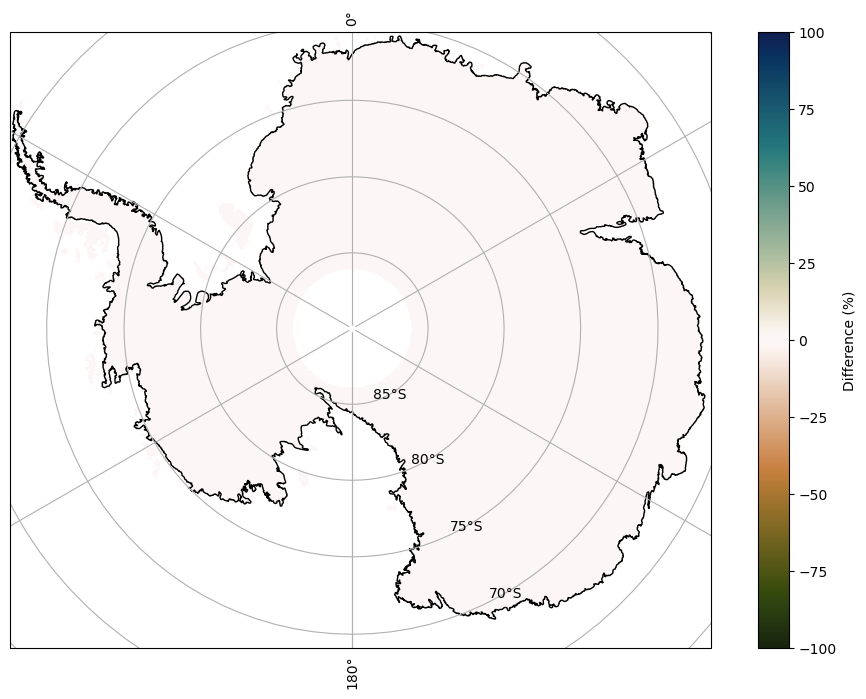

In [15]:
error_percent = (diff/(1000*exfil_analytic))*100

projection = ccrs.SouthPolarStereo()
fig = plt.figure(figsize=(12,8))
ax = plt.subplot(1,1,1, projection=projection)
p1 = ax.pcolormesh(da.x,da.y,error_percent, cmap=cmocean.cm.tarn,vmin = -100, vmax = 100)
scripps_gl.plot(ax=ax, edgecolor="black",linewidth=1,facecolor="none")
ax.gridlines(draw_labels=True)
cb = plt.colorbar(p1)
cb.set_label("Difference (%)")


Text(0.5, 1.0, 'Difference (%)')

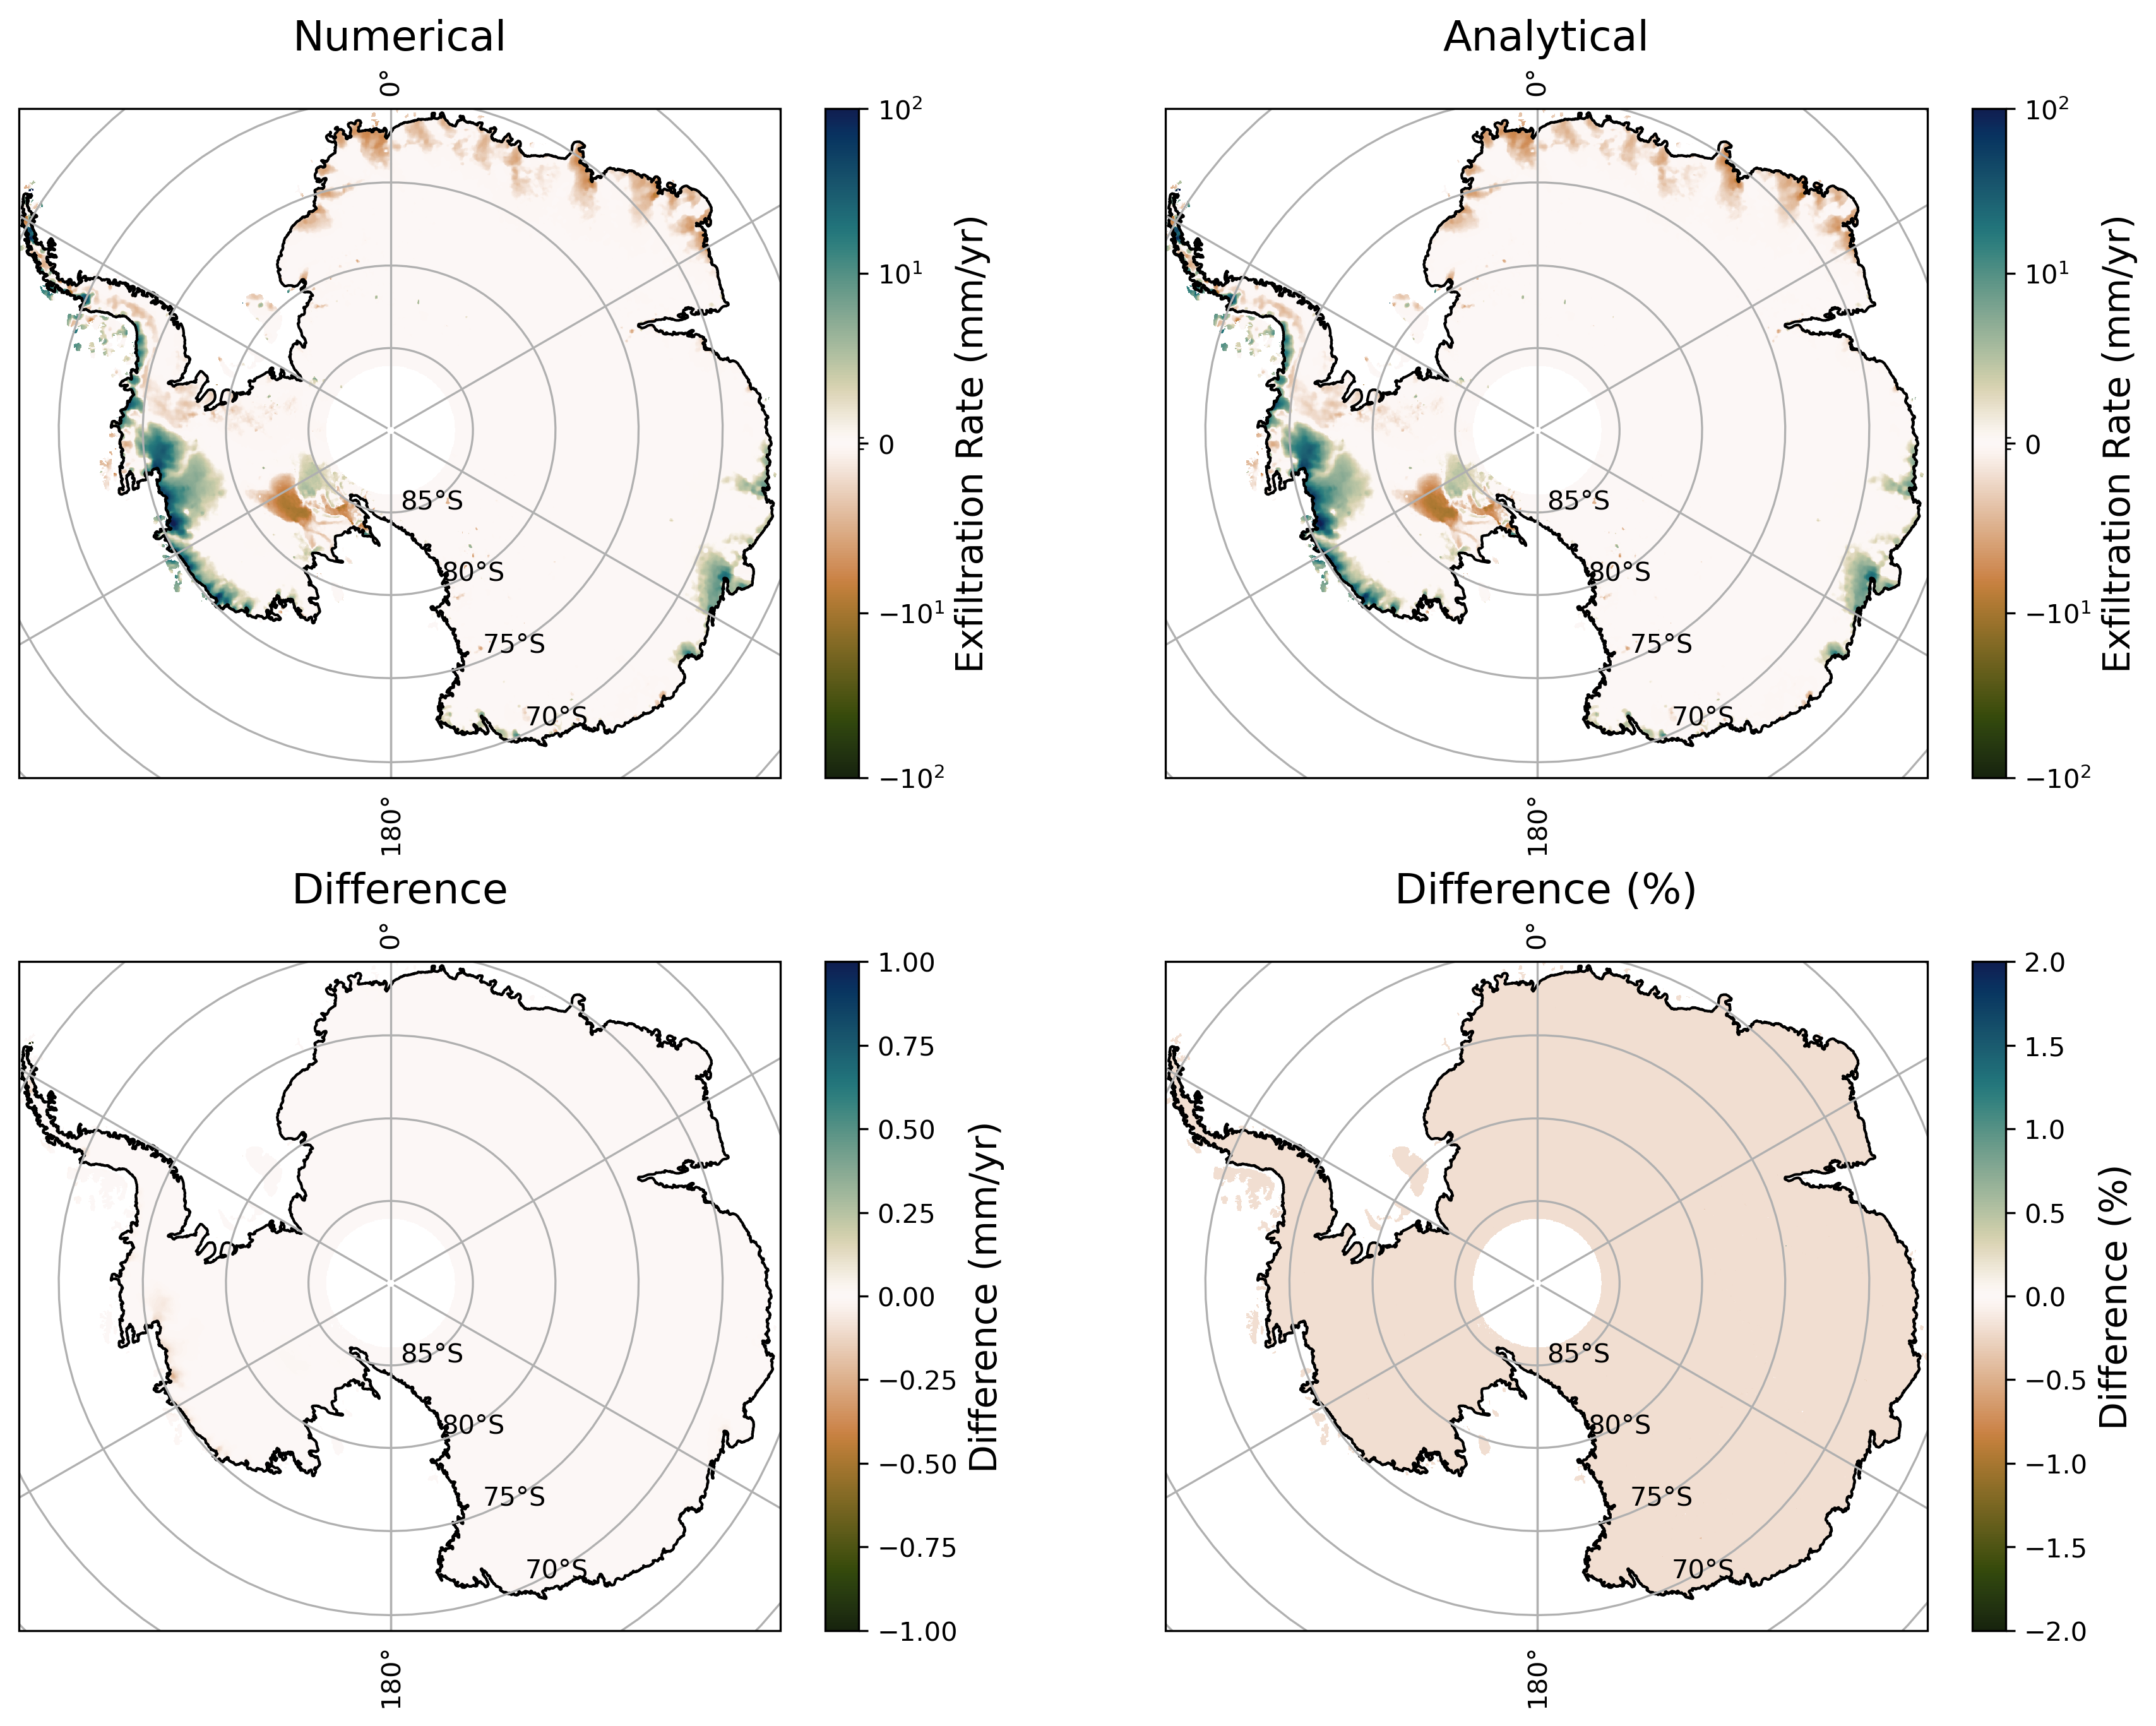

In [18]:
projection = ccrs.SouthPolarStereo()
fig = plt.figure(figsize=(12,9), constrained_layout=True,dpi=300)
ax = plt.subplot(2,2,1, projection=projection)
p1 = ax.pcolormesh(da.x,da.y,-1000*year*sfc_flux_final, cmap=cmocean.cm.tarn,
                   norm=colors.SymLogNorm(linthresh=1.0, linscale=0.03,vmin=-100,vmax=100))
scripps_gl.plot(ax=ax, edgecolor="black",linewidth=1,facecolor="none")
ax.gridlines(draw_labels=True)
plt.title(f"Numerical",fontsize=16)

ax2 = plt.subplot(2,2,2, projection=projection)
p2 = ax2.pcolormesh(da.x,da.y,1000*exfil_analytic, cmap=cmocean.cm.tarn,
                   norm=colors.SymLogNorm(linthresh=1.0, linscale=0.03,vmin=-100,vmax=100))
scripps_gl.plot(ax=ax2, edgecolor="black",linewidth=1,facecolor="none")
ax2.gridlines(draw_labels=True)
plt.title(f"Analytical",fontsize=16)

cbar = fig.colorbar(
    p1,
    ax=ax,                             
    fraction=0.05,                  # thickness
    pad=0.05,                       # distance from subplots
    ticks=[-100, -10, 0, 10, 100]
)
cbar.set_label("Exfiltration Rate (mm/yr)", fontsize=14)
cbar2 = fig.colorbar(
    p2,  
    ax=ax2,                           
    fraction=0.05,                  # thickness
    pad=0.05,                       # distance from subplots
    ticks=[-100, -10, 0, 10, 100]
)
cbar2.set_label("Exfiltration Rate (mm/yr)", fontsize=14)


ax3 = plt.subplot(2,2,3, projection=projection)
p3 = ax3.pcolormesh(da.x,da.y,diff, cmap=cmocean.cm.tarn,vmin = -1, vmax = 1)
scripps_gl.plot(ax=ax3, edgecolor="black",linewidth=1,facecolor="none")
ax3.gridlines(draw_labels=True)
cb3 = plt.colorbar(p3,ax=ax3)
cb3.set_label("Difference (mm/yr)",fontsize=14)
plt.title(f"Difference",fontsize=16)

ax4 = plt.subplot(2,2,4, projection=projection)
p4 = ax4.pcolormesh(da.x,da.y,error_percent, cmap=cmocean.cm.tarn,vmin = -2, vmax = 2)
scripps_gl.plot(ax=ax4, edgecolor="black",linewidth=1,facecolor="none")
ax4.gridlines(draw_labels=True)
cb4 = plt.colorbar(p4,ax=ax4)
cb4.set_label("Difference (%)",fontsize=14)
plt.title(f"Difference (%)",fontsize=16)



In [19]:
np.nanmin(error_percent)

np.float64(-0.454495770158484)

In [20]:
np.nanmean(error_percent)

np.float64(-0.1996887020653166)